# WSCC 3 machines + 3 distributions CIGRE, ECRIT EN ZONES

Le meme reseau que `wscc3sm_cigre3.ipynb`, aux memes valeurs pres, mais ecrit
autrement : la distribution y est decrite **une seule fois**, en numerotation
locale, et **instanciee trois fois**.

`wscc3sm_cigre3.ipynb` ecrit ses 54 bus a plat, dans une seule table numerotee
a la main a partir de 100, 200 et 300. Le reseau CIGRE MT y figure donc trois
fois, a trois numerotations differentes : corriger une impedance de depart
demande trois corrections, et rien ne garantit que les trois copies soient
restees identiques.

Ici, une `Zone` porte le CIGRE MT en numerotation locale (bus 0 = jeu de barres
110 kV du poste, bus 1 a 14 = depart MT), **sans slack** -- une zone ne tient
pas sa propre tension, elle la recoit du transport. Trois `Instance` la
raccordent aux bus 5, 6 et 8 de la WSCC, sous les prefixes 100, 200 et 300, en
agregeant respectivement 4, 3 et 3 departs identiques.

| Qui porte quoi | Pourquoi |
|---|---|
| Le transfo 230/110 kV appartient a l'**instance** | sa puissance depend de `K` et son primaire est le bus amont, deux choses que la zone ignore |
| Le gradin du poste source appartient a l'**instance** | il se dimensionne site par site : 0,35 pu derriere K = 4, 0,25 pu derriere K = 3, ce qui n'est pas un rapport K |
| Les deux transfos 110/20 kV appartiennent a la **zone** | ils se repetent avec elle |

**L'echelle K**, table par table : agreger `K` departs identiques multiplie les
puissances par `K` et divise les impedances par `K`, si bien que les tensions,
les pertes relatives et les dynamiques **en pu** restent celles d'un seul
depart. `T_Lines_pu` fait exception et ne voit multiplier que sa colonne
`Sb_VA`, parce que ses pu sont deja rapportees a cette base.

**La charge residuelle** : chaque bus de charge WSCC doit garder exactement sa
consommation d'origine (125+j50, 90+j30, 100+j35 MVA). `charge_residuelle=True`
retranche donc `K x charge_totale()` de la zone a la charge du bus amont : ce
que la distribution porte, le bus ne le porte plus, et le point de
fonctionnement du transport est celui de la WSCC seule.

`tests/test_zones.py` verifie que l'aplatissement de ce reseau donne, table par
table puis element par element, **la meme matrice `A`** que `wscc3sm_cigre3`.

Base systeme : 100 MVA, 60 Hz. 54 bus, 429 etats.

In [1]:
import sys
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import plotly.graph_objects as go


# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from g2egrid.tables import Tables, assembler  # noqa: E402
from g2egrid.zones import (  # noqa: E402
    Instance,
    Reseau,
    TransfoPoste,
    Zone,
    aplatir,
)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Construction du reseau

### 1.1 Donnees et assemblage

In [2]:
NOM_RESEAU = "WSCC3SM_ZONES"
F_ZOOM = 5.0

f0 = 60.0
Sb = 100e6

# BusType : 1 = slack, 2 = PV, 3 = PQ

# ==========================================================================
# LE TRANSPORT : la WSCC 9 bus d'Anderson et Fouad, dispatch d'origine
# ==========================================================================
# Ses charges sont celles de la WSCC seule. Ce sont les instances qui, plus
# bas, en retranchent ce que la distribution reprend.
TRANSPORT = Tables(
    Y_DER = [ # [BusID, BusType, V_base, V_pu, Theta_rad,  Pg_W, Qg_var,   Pl_W, Ql_var]
            (    1,       1,     16.5e3, 1.040,        0,      0,     0,      0,      0),  # G1
            (    2,       2,     18.0e3, 1.025,        0,  163e6,     0,      0,      0),  # G2
            (    3,       2,     13.8e3, 1.025,        0,   85e6,     0,      0,      0),  # G3
            (    4,       3,      230e3, 1.000,        0,      0,     0,      0,      0),
            (    5,       3,      230e3, 1.000,        0,      0,     0,  125e6,   50e6),  # + CIGRE 1xx
            (    6,       3,      230e3, 1.000,        0,      0,     0,   90e6,   30e6),  # + CIGRE 2xx
            (    7,       3,      230e3, 1.000,        0,      0,     0,      0,      0),
            (    8,       3,      230e3, 1.000,        0,      0,     0,  100e6,   35e6),  # + CIGRE 3xx
            (    9,       3,      230e3, 1.000,        0,      0,     0,      0,      0),
    ],
    T_Lines_pu = [
    # T_Lines_pu : [ID, From, To, Length_km,   R_pu,   X_pu,   B_pu,  Un_V, Sb_VA]
                  (  1,    4,  5,         1, 0.0100, 0.0850, 0.1760, 230e3, 100e6),
                  (  2,    4,  6,         1, 0.0170, 0.0920, 0.1580, 230e3, 100e6),
                  (  3,    5,  7,         1, 0.0320, 0.1610, 0.3060, 230e3, 100e6),
                  (  4,    6,  9,         1, 0.0390, 0.1700, 0.3580, 230e3, 100e6),
                  (  5,    7,  8,         1, 0.0085, 0.0720, 0.1490, 230e3, 100e6),
                  (  6,    8,  9,         1, 0.0119, 0.1008, 0.2090, 230e3, 100e6),
    ],
    T_Transfos = [
     # T_Transfos : [ID, From, To,  Sn_VA,   U1_V,  U2_V,   R_pu,   X_pu]
                   (  1,    1,   4,  100e6, 16.5e3, 230e3,      0, 0.0576),  # G1
                   (  2,    2,   7,  100e6, 18.0e3, 230e3,      0, 0.0625),  # G2
                   (  3,    3,   9,  100e6, 13.8e3, 230e3,      0, 0.0586),  # G3
    ],
    # T_SMs : [ID, BusID, Sn_VA]
    T_SMs = [
        (  1,  1, 247.5e6),
        (  2,  2, 192.0e6),
        (  3,  3, 128.0e6),
    ],
    f0 = f0,
    Sb = Sb,
    nom = NOM_RESEAU,
)

# ==========================================================================
# LA ZONE : un reseau CIGRE MT passif, NUMEROTATION LOCALE, SANS SLACK
# ==========================================================================
# Bus 0 : jeu de barres 110 kV du poste source, c'est le point de raccordement.
# Bus 1 a 14 : le depart MT 20 kV. Les deux transfos 110/20 kV sont dans la
# zone : ils se repetent avec elle. Le transfo de poste, lui, ne l'est pas.
CIGRE_CHARGES = {  # bus local : (P_W, Q_var)
     1: (20.4e6, 1.0e6),  3: (550e3, 50e3),  4: (445e3, 50e3),  5: (750e3, 50e3),
     6:  (565e3,  50e3),  7:  (90e3, 50e3),  8: (605e3, 50e3),  9: (675e3, 50e3),
    10:  (570e3,  50e3), 11: (340e3, 50e3), 12: (205e3, 50e3), 13:  (40e3, 50e3),
    14:  (605e3,  50e3),
}
CIGRE_LIGNES = [  # (de, vers, km, R_ohm/km, X_ohm/km, B_S/km)
    ( 1,  2, 2.82, 0.501, 0.716, 47.493e-6), ( 2,  3, 4.42, 0.501, 0.716, 47.493e-6),
    ( 3,  4, 0.61, 0.501, 0.716, 47.493e-6), ( 4,  5, 0.56, 0.501, 0.716, 47.493e-6),
    ( 5,  6, 1.54, 0.501, 0.716, 47.493e-6), ( 7,  8, 1.67, 0.501, 0.716, 47.493e-6),
    ( 8,  9, 0.32, 0.501, 0.716, 47.493e-6), ( 9, 10, 0.77, 0.501, 0.716, 47.493e-6),
    (10, 11, 0.33, 0.501, 0.716, 47.493e-6), ( 3,  8, 1.30, 0.501, 0.716, 47.493e-6),
    (12, 13, 4.89, 0.510, 0.366,  3.172e-6), (13, 14, 2.99, 0.510, 0.366,  3.172e-6),
]

Y_ZONE = [(0, 3, 110e3, 1.0, 0, 0, 0, 0, 0)]            # PCC 110 kV, PQ et non slack
for _i in range(1, 15):                                  # les 14 bus MT
    _P, _Q = CIGRE_CHARGES.get(_i, (0.0, 0.0))
    Y_ZONE.append((_i, 3, 20e3, 1.0, 0, 0, 0, _P, _Q))

ZONE_CIGRE = Zone(
    tables = Tables(
        Y_DER = Y_ZONE,
        T_Lines_SI = [
            (n, i, j, km, R, X, B)
            for n, (i, j, km, R, X, B) in enumerate(CIGRE_LIGNES, start=1)
        ],
        T_Transfos = [
         # T_Transfos : [ID, From, To, Sn_VA,  U1_V, U2_V,   R_pu, X_pu]
                       (  1,    0,  1,  25e6, 110e3, 20e3, 0.0016, 0.12),  # depart 1
                       (  2,    0, 12,  25e6, 110e3, 20e3, 0.0016, 0.12),  # depart 2
        ],
        f0 = f0,
        Sb = Sb,
        nom = "cigre_mv_passif",
    ),
    bus_pcc = 0,
    nom = "cigre_mv_passif",
)

# ==========================================================================
# LES INSTANCES : trois raccordements de la MEME zone
# ==========================================================================
# Le transfo de poste, pour UN depart : aplatir() multiplie son Sn par K.
TRANSFO_POSTE = TransfoPoste(Sn_VA=50e6, U1_V=230e3, U2_V=110e3,
                             R_pu=0.003, X_pu=0.12)

RESEAU_ZONES = Reseau(
    transport = TRANSPORT,
    zones = {"cigre_mv_passif": ZONE_CIGRE},
    instances = [
     #           zone               prefixe  amont   K   transfo de poste     gradin
     Instance("cigre_mv_passif",        100,     5,  4, transfo=TRANSFO_POSTE,
              charge_residuelle=True, shunt_pcc=0.35),
     Instance("cigre_mv_passif",        200,     6,  3, transfo=TRANSFO_POSTE,
              charge_residuelle=True, shunt_pcc=0.25),
     Instance("cigre_mv_passif",        300,     8,  3, transfo=TRANSFO_POSTE,
              charge_residuelle=True, shunt_pcc=0.25),
    ],
    nom = NOM_RESEAU,
    f_zoom = F_ZOOM,
)

In [3]:
# --- aplatissement, puis g2egrid.tables.assembler ---------------------------
#
# aplatir() emet le transport, puis les instances DANS L'ORDRE, table par
# table. Cet ordre n'est pas cosmetique : l'ordre d'insertion des elements fixe
# l'ordre des etats, donc l'ordre des lignes et des colonnes de A. C'est lui
# qui permet de comparer terme a terme avec le reseau ecrit a plat.
t = aplatir(RESEAU_ZONES)
net = assembler(t)

n_zone = len(ZONE_CIGRE.tables.Y_DER)
print(
    f"{NOM_RESEAU} : {len(t.Y_DER)} bus a plat, dont "
    f"{len(TRANSPORT.Y_DER)} de transport et "
    f"{len(RESEAU_ZONES.instances)} x {n_zone} de distribution"
)
print(
    f"  {len(t.T_Lines_SI) + len(t.T_Lines_pu)} ligne(s), "
    f"{len(t.T_Transfos)} transfo(s), {len(t.T_Shunts)} shunt(s), "
    f"{len(t.T_SMs)} machine(s)"
)
P, Q = ZONE_CIGRE.charge_totale()
print(f"  charge d'UN depart CIGRE : {P / 1e6:.2f} MW, {Q / 1e6:.2f} Mvar")
for inst in RESEAU_ZONES.instances:
    ligne = t.bus(inst.bus_amont)
    print(
        f"  bus {inst.bus_amont} : K = {inst.K}, la distribution porte "
        f"{inst.K * P / 1e6:6.2f} MW, il reste {ligne[7] / 1e6:5.2f} MW "
        "de charge residuelle"
    )

WSCC3SM_ZONES : 54 bus a plat, dont 9 de transport et 3 x 15 de distribution
  42 ligne(s), 12 transfo(s), 3 shunt(s), 3 machine(s)
  charge d'UN depart CIGRE : 25.84 MW, 1.60 Mvar
  bus 5 : K = 4, la distribution porte 103.36 MW, il reste 21.64 MW de charge residuelle
  bus 6 : K = 3, la distribution porte  77.52 MW, il reste 12.48 MW de charge residuelle
  bus 8 : K = 3, la distribution porte  77.52 MW, il reste 22.48 MW de charge residuelle


### 1.2 Load flow

In [4]:
lf = net.run_loadflow()
print(
    f"Load flow : converge en {lf.iterations} iterations (mismatch {lf.mismatch:.2e})\n"
)

print(
    f"{'bus':>4} {'|V| [pu]':>10} {'angle [deg]':>12} "
    f"{'P inj [pu]':>12} {'Q inj [pu]':>12}"
)
print("-" * 54)
for b, i in net._bus_index().items():
    print(
        f"{b:>4} {abs(lf.V[i]):>10.4f} {np.degrees(np.angle(lf.V[i])):>12.4f} "
        f"{lf.S[i].real:>12.4f} {lf.S[i].imag:>12.4f}"
    )
print(
    f"\nSomme des injections : P = {lf.S.real.sum():+.4f} pu, "
    f"Q = {lf.S.imag.sum():+.4f} pu  (= pertes)"
)

Load flow : converge en 6 iterations (mismatch 1.37e-14)

 bus   |V| [pu]  angle [deg]   P inj [pu]   Q inj [pu]
------------------------------------------------------
   1     1.0400       0.0000       0.7760       0.0606
   2     1.0250       8.7137       1.6300      -0.0895
   3     1.0250       4.1930       0.8500      -0.2444
   4     1.0375      -2.3409       0.0000       0.0000
   5     1.0177      -4.2390      -0.2164      -0.4360
   6     1.0315      -3.9584      -0.1248      -0.2520
   7     1.0352       3.2397      -0.0000       0.0000
   8     1.0303       0.2672      -0.2248      -0.3020
   9     1.0401       1.5481      -0.0000       0.0000
 100     1.0249      -7.6984       0.0000       0.0000
 101     1.0090     -14.4141      -0.8160      -0.0400
 102     0.9897     -15.6988       0.0000      -0.0000
 103     0.9599     -17.7933      -0.0220      -0.0020
 104     0.9584     -17.9078      -0.0178      -0.0020
 105     0.9574     -17.9871      -0.0300      -0.0020
 106   

## 2. Modele d'etat

Equilibre element par element (Newton sur `[f; g] = 0`), puis assemblage
global : cablage des ports par LFT, elimination des variables algebriques
par complement de Schur.

In [5]:
net.solve_equilibrium()
ss = net.build_state_space()

print(ss)
print(f"\n{len(ss.states)} etats, {len(ss.inputs)} entrees, {len(ss.outputs)} sorties")
print(f"stable : {ss.is_stable()}   max Re(lambda) = {ss.eig().real.max():+.4e}")

print("\nEtats par element :")
seen = []
for s in ss.states:
    owner = s.split(".")[0]
    if owner not in seen:
        seen.append(owner)
for owner in seen:
    noms = [s.split(".", 1)[1] for s in ss.states if s.startswith(owner + ".")]
    print(f"  {owner:<12} {len(noms):>3} : {', '.join(noms)}")

<StateSpace 429 etats, 91 entrees, 384 sorties | max Re(lambda)=+4.872e-12>

429 etats, 91 entrees, 384 sorties


stable : True   max Re(lambda) = +4.8719e-12

Etats par element :
  bus4           2 : vd, vq
  bus5           2 : vd, vq
  bus6           2 : vd, vq
  bus7           2 : vd, vq
  bus8           2 : vd, vq
  bus9           2 : vd, vq
  bus100         2 : vd, vq
  bus101         2 : vd, vq
  bus102         2 : vd, vq
  bus103         2 : vd, vq
  bus104         2 : vd, vq
  bus105         2 : vd, vq
  bus106         2 : vd, vq
  bus107         2 : vd, vq
  bus108         2 : vd, vq
  bus109         2 : vd, vq
  bus110         2 : vd, vq
  bus111         2 : vd, vq
  bus112         2 : vd, vq
  bus113         2 : vd, vq
  bus114         2 : vd, vq
  bus200         2 : vd, vq
  bus201         2 : vd, vq
  bus202         2 : vd, vq
  bus203         2 : vd, vq
  bus204         2 : vd, vq
  bus205         2 : vd, vq
  bus206         2 : vd, vq
  bus207         2 : vd, vq
  bus208         2 : vd, vq
  bus209         2 : vd, vq
  bus210         2 : vd, vq
  bus211         2 : vd, vq
  bus212  

### 2.1 Tableau modal

Une ligne par valeur propre, triee par partie reelle decroissante (modes les
plus lents d'abord), comme `displayModalAnalysis` en MATLAB : une paire
conjuguee occupe deux lignes. L'index `Mode` est l'indice `k` de `lam[k]`.

| Colonne | Definition |
|---|---|
| `Re`, `Im` | parties reelle [1/s] et imaginaire [rad/s] de la valeur propre |
| `f_und [Hz]` | frequence propre non amortie, `abs(lambda) / 2pi` |
| `f_dam [Hz]` | frequence d'oscillation, `abs(Im) / 2pi` |
| `zeta [%]` | amortissement, `-Re / abs(lambda)` |
| `Etat j`, `%j` | j-ieme etat le plus participant et sa participation `abs(v_ki . w_ik)`, normalisee a 100 % par mode |

In [6]:
lam, Vr = np.linalg.eig(ss.A)
Wl = np.linalg.inv(Vr)
Pf = np.abs(Vr.T) * np.abs(Wl)  # Pf[k, i] : participation de l'etat i au mode k
Pf = Pf / np.maximum(Pf.sum(axis=1, keepdims=True), 1e-30)
top3 = np.argsort(-Pf, axis=1)[:, :3]  # les trois etats les plus participants
k = np.arange(len(lam))

mag = np.abs(lam)
zeta = np.where(mag > 1e-10, -lam.real / np.where(mag > 1e-10, mag, 1.0), 0.0)

T_eig = pd.DataFrame(
    {
        "Re": lam.real,
        "Im": lam.imag,
        "f_und [Hz]": mag / (2 * np.pi),
        "f_dam [Hz]": np.abs(lam.imag) / (2 * np.pi),
        "zeta [%]": 100 * zeta,
    }
)
for j in range(3):
    T_eig[f"Etat {j + 1}"] = [ss.states[i] for i in top3[:, j]]
    T_eig[f"%{j + 1}"] = 100 * Pf[k, top3[:, j]]
T_eig = T_eig.iloc[np.argsort(-lam.real, kind="stable")]
T_eig.index.name = "Mode"



T_eig

,Re,Im,f_und [Hz],f_dam [Hz],zeta [%],Etat 1,%1,Etat 2,%2,Etat 3,%3
Mode,,,,,,,,,,,
336,2.612476e-11,0.0,4.157884e-12,0.0,0.0,SM1.theta,43.362131,SM2.theta,34.067961,SM3.theta,22.569908
342,-1.799446e-01,0.0,2.863907e-02,0.0,100.0,SM1.vpss,40.010718,SM2.vpss,28.996548,SM3.vpss,23.312733
343,-1.872456e-01,0.0,2.980107e-02,0.0,100.0,SM1.vpss,47.852680,SM2.vpss,45.473465,SM3.vpss,2.317386
344,-1.889712e-01,0.0,3.007571e-02,0.0,100.0,SM3.vpss,66.923195,SM2.vpss,19.421555,SM1.vpss,6.036336
341,-4.858830e-01,0.0,7.733067e-02,0.0,100.0,SM1.v1,40.897268,SM2.v1,24.986856,SM3.v1,19.197272
...,...,...,...,...,...,...,...,...,...,...,...
3,-3.050455e+05,0.0,4.854951e+04,0.0,100.0,T1_1_4.i_q,49.128285,SM1.phi_d,38.286705,T1_1_4.i_d,12.514417
5,-3.057249e+05,0.0,4.865763e+04,0.0,100.0,T2_2_7.i_q,56.373334,SM2.phi_q,32.455278,T2_2_7.i_d,11.095772
4,-3.143132e+05,0.0,5.002449e+04,0.0,100.0,T2_2_7.i_d,54.832041,SM2.phi_d,34.311994,T2_2_7.i_q,10.785793


### 2.2 Carte des valeurs propres

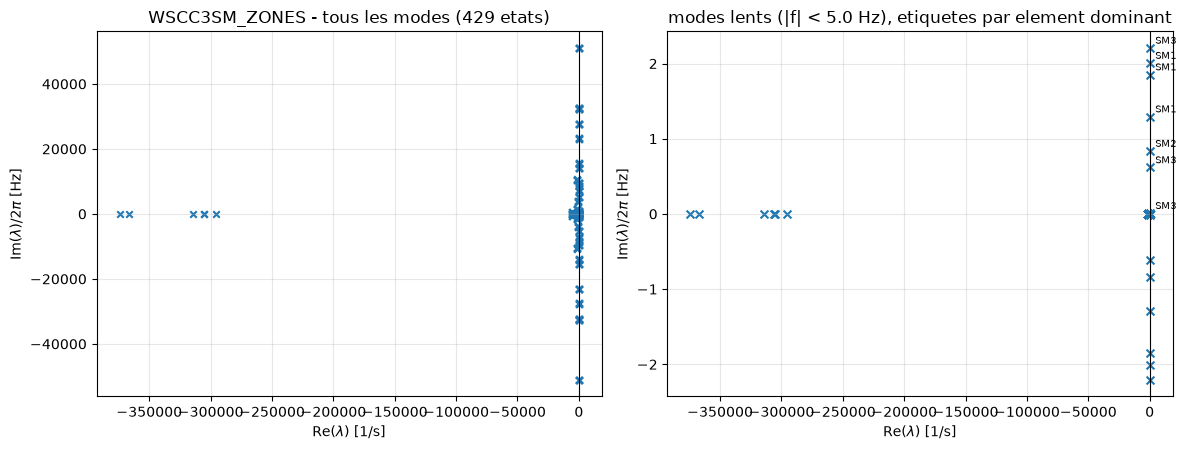

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].scatter(lam.real, lam.imag / (2 * np.pi), s=22, marker="x")
ax[0].axvline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("Re($\\lambda$) [1/s]")
ax[0].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[0].set_title(f"{NOM_RESEAU} - tous les modes ({len(lam)} etats)")
ax[0].grid(True, alpha=0.3)

zoom = np.abs(lam.imag) / (2 * np.pi) <= F_ZOOM
ax[1].scatter(lam[zoom].real, lam[zoom].imag / (2 * np.pi), s=32, marker="x")
for k in np.flatnonzero(zoom & (lam.imag > 1e-6)):
    ax[1].annotate(
        ss.states[top3[k, 0]].split(".")[0],
        (lam[k].real, lam[k].imag / (2 * np.pi)),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax[1].axvline(0.0, color="k", lw=0.8)
ax[1].set_xlabel("Re($\\lambda$) [1/s]")
ax[1].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[1].set_title(f"modes lents (|f| < {F_ZOOM} Hz), etiquetes par element dominant")
ax[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=T_eig["Re"], y=T_eig["Im"], mode="markers"))

fig.update_xaxes(range=[-1000, 10])
fig.update_yaxes(range=[-10, 1000])
fig.show()